# California Housing Price Prediction

Predicting the median house value of California census block groups with a Random Forest, and testing whether stronger regularization actually helps on unseen data.

In [1]:
### IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

## 1. Data acquisition

In [2]:
# Fetch the California Housing dataset as a pandas DataFrame
housing = fetch_california_housing(as_frame=True)
df = housing.frame
df.shape

(20640, 9)

## 2. Exploratory data analysis

In [3]:
# Structure and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
# Missing values and summary statistics
print("Missing values per column:")
print(df.isnull().sum())
df.describe().T

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


992 of 20640 block groups (4.8%) sit at the $500,000 cap


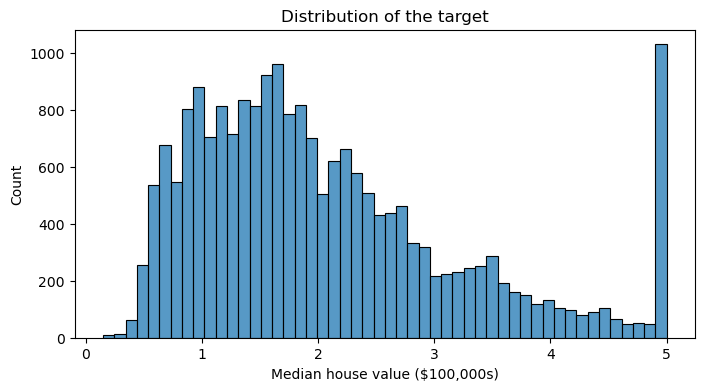

In [5]:
# Target distribution. MedHouseVal is in $100,000s and capped at 5.0 ($500,000)
capped = (df['MedHouseVal'] >= 5.0).sum()
print(f"{capped} of {len(df)} block groups ({capped / len(df):.1%}) sit at the $500,000 cap")

plt.figure(figsize=(8, 4))
sns.histplot(df['MedHouseVal'], bins=50)
plt.xlabel('Median house value ($100,000s)')
plt.title('Distribution of the target')
plt.show()

In [6]:
# Correlation of each feature with the target (price)
corr_with_target = df.corr()['MedHouseVal'].drop('MedHouseVal').sort_values(ascending=False)
print(corr_with_target.round(3))

MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144
Name: MedHouseVal, dtype: float64


## 3. Train / test split

80/20 split with a fixed `random_state`. The test set is used **only once**, at the end. Every modelling decision below is made with cross-validation on the training set.

In [7]:
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Same 3 folds for every model, so the cross-validation scores are comparable
cv = KFold(n_splits=3, shuffle=True, random_state=42)

## 4. Baseline models

* **Random Forest (unconstrained):** 200 trees, default depth. Tree models do not need feature scaling, so no scaler is used.
* **Linear Regression (reference):** a simple model for context. This one *does* need scaling, so it is wrapped in a `Pipeline` with `StandardScaler`.

In [8]:
baseline_rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
baseline_rf.fit(X_train, y_train)
baseline_cv = cross_val_score(baseline_rf, X_train, y_train, cv=cv, scoring='r2').mean()

linear_model = Pipeline(steps=[('scaler', StandardScaler()), ('model', LinearRegression())])
linear_model.fit(X_train, y_train)
linear_cv = cross_val_score(linear_model, X_train, y_train, cv=cv, scoring='r2').mean()

print(f"Baseline RF cross-validated R2:   {baseline_cv:.4f}")
print(f"Linear regression CV R2:          {linear_cv:.4f}")

Baseline RF cross-validated R2:   0.8014
Linear regression CV R2:          0.6112


## 5. Hyperparameter tuning

In [9]:
# 1. Strict grid
strict_grid = {
    'max_depth': [4, 6, 8],
    'min_samples_split': [15, 20],
    'min_samples_leaf': [5, 10],
}
strict_search = GridSearchCV(
    RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    param_grid=strict_grid, cv=cv, scoring='r2', n_jobs=1, verbose=1
)
strict_search.fit(X_train, y_train)
print("Strict grid  best params:", strict_search.best_params_)
print(f"Strict grid  best CV R2: {strict_search.best_score_:.4f}")

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Strict grid  best params: {'max_depth': 8, 'min_samples_leaf': 5, 'min_samples_split': 15}
Strict grid  best CV R2: 0.7526


In [10]:
# 2. Wide grid 
wide_grid = {
    'max_depth': [None, 12, 20],
    'min_samples_leaf': [1, 2, 5],
    'max_features': [1.0, 0.5],
}
wide_search = GridSearchCV(
    RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    param_grid=wide_grid, cv=cv, scoring='r2', n_jobs=1, verbose=1
)
wide_search.fit(X_train, y_train)
print("Wide grid    best params:", wide_search.best_params_)
print(f"Wide grid    best CV R2: {wide_search.best_score_:.4f}")

# Top candidates from the wide search
cols = ['param_max_depth', 'param_min_samples_leaf', 'param_max_features', 'mean_test_score']
pd.DataFrame(wide_search.cv_results_)[cols].sort_values('mean_test_score', ascending=False).head(8)

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Wide grid    best params: {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 1}
Wide grid    best CV R2: 0.8105


,param_max_depth,param_min_samples_leaf,param_max_features,mean_test_score
15,20,1,0.5,0.810477
3,None,1,0.5,0.810401
4,None,2,0.5,0.809343
16,20,2,0.5,0.808847
5,None,5,0.5,0.802927
17,20,5,0.5,0.802475
13,20,2,1.0,0.801829
1,None,2,1.0,0.801791


## 6. Model selection and final evaluation

The final Random Forest is chosen by its **cross-validated score on the training set only**. Test metrics are then reported for every model, but they play no part in the choice.

In [11]:
def evaluate(name, estimator, cv_r2):
    pred_train = estimator.predict(X_train)
    pred_test = estimator.predict(X_test)
    r2_train = r2_score(y_train, pred_train)
    r2_test = r2_score(y_test, pred_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred_test))   # in $100,000s
    return {
        'Model': name,
        'CV R2 (train only)': cv_r2,
        'Train R2': r2_train,
        'Test R2': r2_test,
        'Gap (train - test)': r2_train - r2_test,
        'Test RMSE ($)': rmse * 100000,
    }

rf_candidates = {
    'RF baseline (unconstrained)': (baseline_rf, baseline_cv),
    'RF strict-regularized': (strict_search.best_estimator_, strict_search.best_score_),
    'RF tuned (wide grid)': (wide_search.best_estimator_, wide_search.best_score_),
}

rows = [evaluate(name, est, score) for name, (est, score) in rf_candidates.items()]
rows.append(evaluate('Linear regression (reference)', linear_model, linear_cv))
results = pd.DataFrame(rows).set_index('Model')


final_name = max(rf_candidates, key=lambda n: rf_candidates[n][1])
final_model = rf_candidates[final_name][0]

print(f"Final model selected by CV: {final_name}\n")
results.round(4)

Final model selected by CV: RF tuned (wide grid)



,CV R2 (train only),Train R2,Test R2,Gap (train - test),Test RMSE ($)
Model,,,,,
RF baseline (unconstrained),0.8014,0.9742,0.8062,0.1680,50394.0431
RF strict-regularized,0.7526,0.7989,0.7395,0.0594,58422.5042
RF tuned (wide grid),0.8105,0.9733,0.8132,0.1601,49476.7521
Linear regression (reference),0.6112,0.6126,0.5758,0.0368,74558.1383


## 7. Feature importance (final model)

   Feature  Importance
    MedInc       0.441
  AveOccup       0.131
  Latitude       0.111
 Longitude       0.108
  AveRooms       0.090
  HouseAge       0.054
 AveBedrms       0.036
Population       0.030


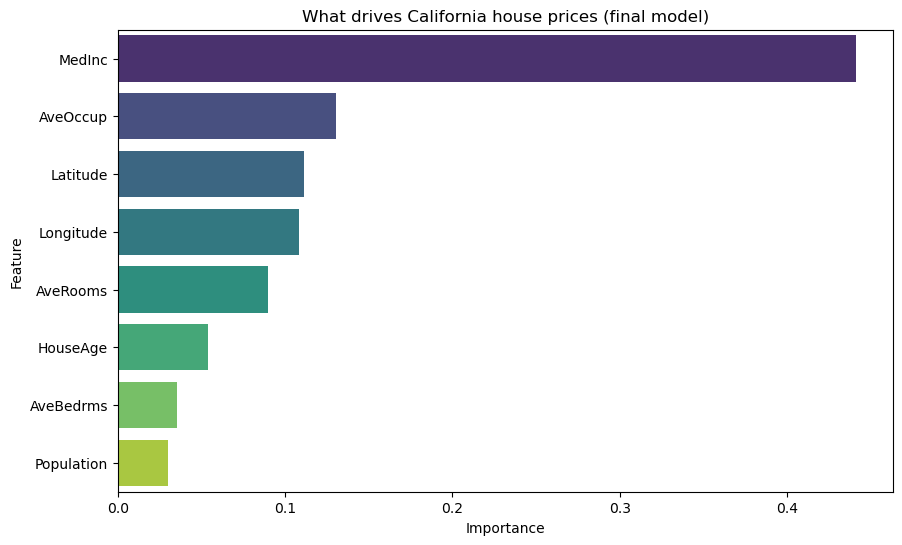

In [13]:
importance_df = (
    pd.DataFrame({'Feature': X.columns, 'Importance': final_model.feature_importances_})
    .sort_values('Importance', ascending=False)
)
print(importance_df.round(3).to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title('What drives California house prices (final model)')
plt.show()